# Versión reproducible - FASE2

Proyecto Bike Sharing Analytics.

Adaptación del notebook académico original.

Se utiliza el dataset local data/day.csv.
Los resultados nuevos se guardan por separado.

Instalar previamente requirements.txt.

Los algoritmos y parámetros originales se conservan.

La ejecución integral está pendiente de validación.

Notebook de origen:
notebooks/evidencias/Fases_2_3/fase 2 y fase 3/fase 2/Proyecto_Integrador_Bicicletas_Final.ipynb

In [1]:

# Localizar la raíz del repositorio.

from pathlib import Path
import sys
import hashlib

actual = Path.cwd().resolve()

candidatos = [actual, *actual.parents]

# Alternativa para Google Colab.

candidatos.append(
    Path("/content/Bike-Sharing-Analytics")
)

ROOT = next(
    (
        p for p in candidatos
        if (p / "data" / "day.csv").is_file()
        and (p / "requirements.txt").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Descarga o clona el repositorio antes de ejecutar."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.config import DATASET, RESULTS_DIR

HASH_ESPERADO = (
    "a6bcf826782d3c0fbfdcbeead17cd0884"
    "185a0dafe8ff10cd48a874ee7ba18be"
)

assert hashlib.sha256(
    DATASET.read_bytes()
).hexdigest() == HASH_ESPERADO

print("Repositorio:", ROOT)
print("Dataset:", DATASET)
print("Integridad del dataset: OK")


Repositorio: /content/Bike-Sharing-Analytics
Dataset: /content/Bike-Sharing-Analytics/data/day.csv
Integridad del dataset: OK


# Proyecto Integrador — Predicción de demanda de bicicletas
**Universidad de La Salle · Ciencia de Datos · 15 de noviembre de 2026**

**Fuente:** UCI Bike Sharing (`day.csv`). **Objetivo:** predecir `cnt` con regresión y evaluar generalización cronológica. Se usa una sola partición **70 % entrenamiento / 15 % validación / 15 % prueba**, sin mezclar resultados del experimento anterior 80/20.

**Orden de ejecución:** Runtime → Run all. La descarga del dataset requiere conexión o carga manual. La sección R es complementaria y requiere `Rscript` (se puede instalar en Colab). Las celdas no incluyen métricas inventadas; se calculan al ejecutarlas.

In [2]:

# Las dependencias deben instalarse previamente
# mediante requirements.txt.

print("Utilizando el entorno previamente configurado.")


Utilizando el entorno previamente configurado.


In [3]:
import io, zipfile, urllib.request, subprocess, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

SEMILLA = 42
SALIDA = RESULTS_DIR / "reproduccion" / "fase2"
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
print('Librerías listas. Carpeta:', SALIDA.resolve())

Librerías listas. Carpeta: /content/Bike-Sharing-Analytics/results/reproduccion/fase2


## 1. Descarga y examen de `day.csv`
Se intenta descargar desde UCI; si falla, se solicita cargar el archivo manualmente.

In [4]:

# Cargar el dataset incluido en el repositorio.

datos = pd.read_csv(DATASET)

print("Dataset local cargado correctamente.")
print("Dimensiones:", datos.shape)

display(datos.head())

print("Columnas:", datos.columns.tolist())


Dataset local cargado correctamente.
Dimensiones: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Columnas: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


## 2. Calidad, nulos y mecanismos MCAR/MAR/MNAR
**MCAR:** ausencia independiente de variables observadas y no observadas; **MAR:** ausencia explicable por variables observadas; **MNAR:** ausencia dependiente de información no observada. Se diagnostican **las 16 columnas** antes de imputar. Si no hay nulos, no hay mecanismo observable que clasificar ni justificación para aplicar media, mediana, KNNImputer, IterativeImputer o eliminación. Si hubiera nulos, el notebook se detiene para investigar sus patrones y posibles causas antes de elegir tratamiento.

In [5]:
requeridas = ['instant','dteday','season','yr','mnth','holiday','weekday','workingday','weathersit','temp','atemp','hum','windspeed','casual','registered','cnt']
assert set(requeridas).issubset(datos.columns), 'Faltan columnas del dataset original'
df = datos.copy()
df['dteday'] = pd.to_datetime(df['dteday'], errors='coerce')
df = df.sort_values('dteday').reset_index(drop=True)
nulos = df.isna().sum().to_frame('Valores faltantes')
nulos['Porcentaje (%)'] = (df.isna().mean()*100).round(2)
display(nulos)
print('Fechas duplicadas:', df.dteday.duplicated().sum())
print('Período:',df.dteday.min().date(),'a',df.dteday.max().date())
print('Alquileres promedio:',round(df.cnt.mean(),2))
assert df.isna().sum().sum() == 0, 'Hay nulos: analizar MCAR/MAR/MNAR antes de imputar'
assert not df.dteday.duplicated().any(), 'Hay fechas duplicadas'
assert (df.casual + df.registered == df.cnt).all(), 'Inconsistencia en cnt'
print('Sin imputación: no existen datos faltantes.')
df.to_csv(SALIDA/'datos_ordenados.csv',index=False)

,Valores faltantes,Porcentaje (%)
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0
temp,0,0.0


Fechas duplicadas: 0
Período: 2011-01-01 a 2012-12-31
Alquileres promedio: 4504.35
Sin imputación: no existen datos faltantes.


## 3. Detección y decisión sobre outliers
El método IQR detecta observaciones fuera de Q1 − 1,5×IQR y Q3 + 1,5×IQR. Se inspeccionan `cnt`, `temp`, `hum` y `windspeed` **solo para diagnóstico**. Se conservarán inicialmente los valores extremos: pueden corresponder a clima real; eliminar o winsorizar puede descartar señal. No se estiman umbrales sobre validación/prueba para transformar predictores. Si posteriormente se ensaya winsorización, sus percentiles deberán ajustarse exclusivamente en entrenamiento.

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,Porcentaje
0,cnt,3152.000,5956.000,2804.000,-1054.000,10162.000,0,0.000
1,temp,0.337,0.655,0.318,-0.140,1.133,0,0.000
2,hum,0.520,0.730,0.210,0.205,1.046,2,0.274
3,windspeed,0.135,0.233,0.098,-0.012,0.381,13,1.778


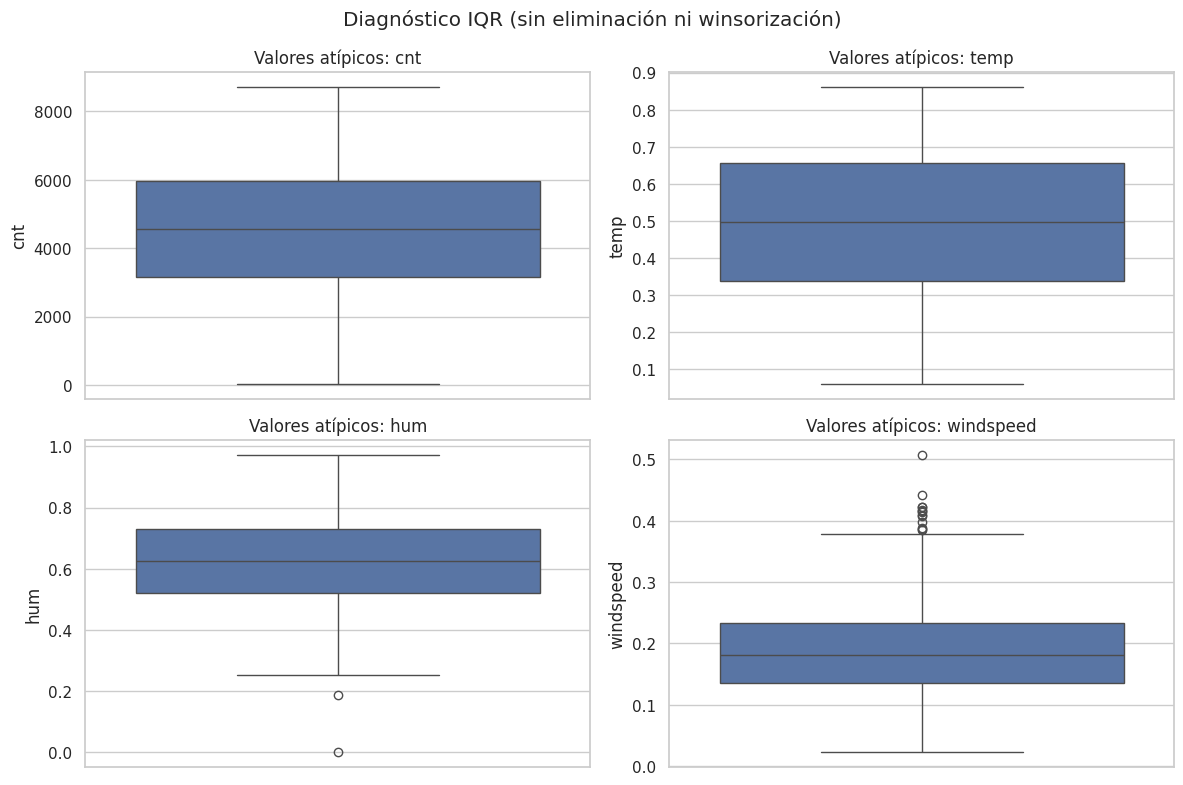

Decisión: conservar observaciones; no aplicar imputación ni recorte.


In [6]:
variables_outliers=['cnt','temp','hum','windspeed']
filas=[]
for variable in variables_outliers:
    q1,q3=df[variable].quantile([.25,.75]); iqr=q3-q1
    li,ls=q1-1.5*iqr,q3+1.5*iqr
    cantidad=int(((df[variable]<li)|(df[variable]>ls)).sum())
    filas.append({'Variable':variable,'Q1':q1,'Q3':q3,'IQR':iqr,'Límite inferior':li,'Límite superior':ls,'Outliers':cantidad,'Porcentaje':100*cantidad/len(df)})
tabla_outliers=pd.DataFrame(filas)
display(tabla_outliers.round(3))
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axs.flat,variables_outliers):
    sns.boxplot(y=df[col],ax=ax); ax.set_title('Valores atípicos: '+col)
fig.suptitle('Diagnóstico IQR (sin eliminación ni winsorización)')
fig.tight_layout();fig.savefig(SALIDA/'01_outliers.png',dpi=150);plt.show()
print('Decisión: conservar observaciones; no aplicar imputación ni recorte.')

## 4. Ingeniería de características
- `fin_de_semana`: indicador de sábado/domingo, para capturar movilidad recreativa.
- `temp_hum_interaccion`: producto de temperatura y humedad normalizadas, para representar su efecto conjunto.

**Fuga de información:** `casual` y `registered` se excluyen siempre porque su suma es exactamente `cnt`. Las dos variables derivadas no utilizan el objetivo.

In [7]:
df_modelo=df.copy()
df_modelo['fin_de_semana']=(df_modelo.dteday.dt.weekday>=5).astype(int)
df_modelo['temp_hum_interaccion']=df_modelo['temp']*df_modelo['hum']
assert df_modelo.fin_de_semana.isin([0,1]).all()
assert df_modelo.temp_hum_interaccion.notna().all()
display(df_modelo[['dteday','temp','hum','fin_de_semana','temp_hum_interaccion','cnt']].head(10))
print('Dimensiones:',df_modelo.shape)
print(df_modelo.fin_de_semana.value_counts())

,dteday,temp,hum,fin_de_semana,temp_hum_interaccion,cnt
0,2011-01-01,0.344167,0.805833,1,0.277341,985
1,2011-01-02,0.363478,0.696087,1,0.253012,801
2,2011-01-03,0.196364,0.437273,0,0.085865,1349
3,2011-01-04,0.200000,0.590435,0,0.118087,1562
4,2011-01-05,0.226957,0.436957,0,0.099170,1600
5,2011-01-06,0.204348,0.518261,0,0.105906,1606
6,2011-01-07,0.196522,0.498696,0,0.098005,1510
7,2011-01-08,0.165000,0.535833,1,0.088412,959
8,2011-01-09,0.138333,0.434167,1,0.060060,822
9,2011-01-10,0.150833,0.482917,0,0.072840,1321


Dimensiones: (731, 18)
fin_de_semana
0    521
1    210
Name: count, dtype: int64


## 5. División cronológica 70/15/15
Se respeta el orden temporal: entrenamiento para ajustar parámetros, validación para comparar modelos y prueba **una sola vez** para evaluar el modelo elegido. No aplica `StratifiedSplit`, SMOTE, ADASYN ni `class_weight`, porque `cnt` es una variable continua y la tarea es de regresión.

In [8]:
df_modelo=df_modelo.sort_values('dteday').reset_index(drop=True)
n=len(df_modelo);n_train=int(n*.70);n_val=int(n*.15)
train_df=df_modelo.iloc[:n_train].copy()
val_df=df_modelo.iloc[n_train:n_train+n_val].copy()
test_df=df_modelo.iloc[n_train+n_val:].copy()
for nombre,conjunto in [('Entrenamiento',train_df),('Validación',val_df),('Prueba',test_df)]:
    print(nombre,len(conjunto),conjunto.dteday.min().date(),'a',conjunto.dteday.max().date())
assert len(train_df)+len(val_df)+len(test_df)==len(df_modelo)
assert train_df.dteday.max()<val_df.dteday.min()<test_df.dteday.min()
print('Partición cronológica correcta.')

Entrenamiento 511 2011-01-01 a 2012-05-25
Validación 109 2012-05-26 a 2012-09-11
Prueba 111 2012-09-12 a 2012-12-31
Partición cronológica correcta.


## 6. Codificación y escalamiento sin fuga de información
`StandardScaler` para continuas y `OneHotEncoder` para categóricas. Se llama a `fit_transform` **solo con entrenamiento** y a `transform` con validación y prueba. La fecha no entra como predictor directo; `yr` representa el año. La transformación `OneHotEncoder` trata los códigos de estación y clima como categorías, no como magnitudes.

In [9]:
variables_numericas=['temp','hum','windspeed','temp_hum_interaccion']
variables_categoricas=['season','weathersit','workingday','yr','fin_de_semana']
variables_modelo=variables_numericas+variables_categoricas
X_train=train_df[variables_modelo].copy();y_train=train_df['cnt'].copy()
X_val=val_df[variables_modelo].copy();y_val=val_df['cnt'].copy()
X_test=test_df[variables_modelo].copy();y_test=test_df['cnt'].copy()
preprocesador=ColumnTransformer([
    ('numericas',Pipeline([('escalador',StandardScaler())]),variables_numericas),
    ('categoricas',Pipeline([('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),variables_categoricas)
])
X_train_procesado=preprocesador.fit_transform(X_train)
X_val_procesado=preprocesador.transform(X_val)
X_test_procesado=preprocesador.transform(X_test)
for nombre,x in [('Entrenamiento',X_train_procesado),('Validación',X_val_procesado),('Prueba',X_test_procesado)]: print(nombre,x.shape)
assert X_train_procesado.shape[1]==X_val_procesado.shape[1]==X_test_procesado.shape[1]
assert 'casual' not in variables_modelo and 'registered' not in variables_modelo
print('Codificación y escalamiento sin fuga de datos: verificados.')

Entrenamiento (511, 17)
Validación (109, 17)
Prueba (111, 17)
Codificación y escalamiento sin fuga de datos: verificados.


## 7. Modelo baseline: regresión lineal simple
Se ajusta con `temp` exclusivamente en entrenamiento y se evalúa sobre validación. Es una referencia simple para comparar modelos; no se requiere escalamiento para esta regresión lineal univariada.

In [10]:
modelo_baseline=LinearRegression().fit(train_df[['temp']],y_train)
pred_baseline_val=modelo_baseline.predict(val_df[['temp']])
def metricas(real,pred):
    return {'MAE':mean_absolute_error(real,pred),'RMSE':np.sqrt(mean_squared_error(real,pred)),'R2':r2_score(real,pred)}
met_baseline=metricas(y_val,pred_baseline_val)
mae_baseline=met_baseline['MAE'];rmse_baseline=met_baseline['RMSE'];r2_baseline=met_baseline['R2']
display(pd.DataFrame([{'Modelo':'Regresión lineal simple',**met_baseline}]).round(4))
print('Coeficiente:',modelo_baseline.coef_[0],'Intercepto:',modelo_baseline.intercept_)
assert np.isfinite(pred_baseline_val).all()

,Modelo,MAE,RMSE,R2
0,Regresión lineal simple,1681.2355,1894.8082,-3.9577


Coeficiente: 5512.411790333314 Intercepto: 1225.3488108183424


## 8. Modelo múltiple y selección con validación
Se entrena con las características procesadas. El criterio primario de selección es **MAE de validación**; también se reportan RMSE y R². El R² negativo indica rendimiento inferior a predecir la media de ese mismo conjunto evaluado; no debe ocultarse.

In [11]:
modelo_multiple=LinearRegression().fit(X_train_procesado,y_train)
pred_multiple_val=modelo_multiple.predict(X_val_procesado)
met_multiple=metricas(y_val,pred_multiple_val)
mae_multiple=met_multiple['MAE'];rmse_multiple=met_multiple['RMSE'];r2_multiple=met_multiple['R2']
comparacion_modelos=pd.DataFrame([{'Modelo':'Regresión lineal simple',**met_baseline},{'Modelo':'Regresión lineal múltiple',**met_multiple}])
display(comparacion_modelos.round(4))
mejora_mae=100*(mae_baseline-mae_multiple)/mae_baseline
print(f'Mejora relativa de MAE: {mejora_mae:.2f}%')
modelo_elegido='multiple' if mae_multiple<mae_baseline else 'simple'
print('Modelo seleccionado según MAE de validación:',modelo_elegido)
assert np.isfinite(pred_multiple_val).all()
comparacion_modelos.to_csv(SALIDA/'metricas_validacion.csv',index=False)

,Modelo,MAE,RMSE,R2
0,Regresión lineal simple,1681.2355,1894.8082,-3.9577
1,Regresión lineal múltiple,730.2825,919.6126,-0.1678


Mejora relativa de MAE: 56.56%
Modelo seleccionado según MAE de validación: multiple


## 9. Evaluación final en prueba
Una vez seleccionado el modelo en validación, se usa el conjunto de prueba **sin reentrenar ni reajustar el preprocesamiento**. Las métricas de prueba son finales, no sirven para seleccionar otra configuración. Si los resultados difieren entre validación y prueba, se interpreta como posible cambio de distribución temporal, no como error de ejecución.

,Conjunto,MAE,RMSE,R2
0,Validación,730.2825,919.6126,-0.1678
1,Prueba,937.7764,1231.9848,0.6218


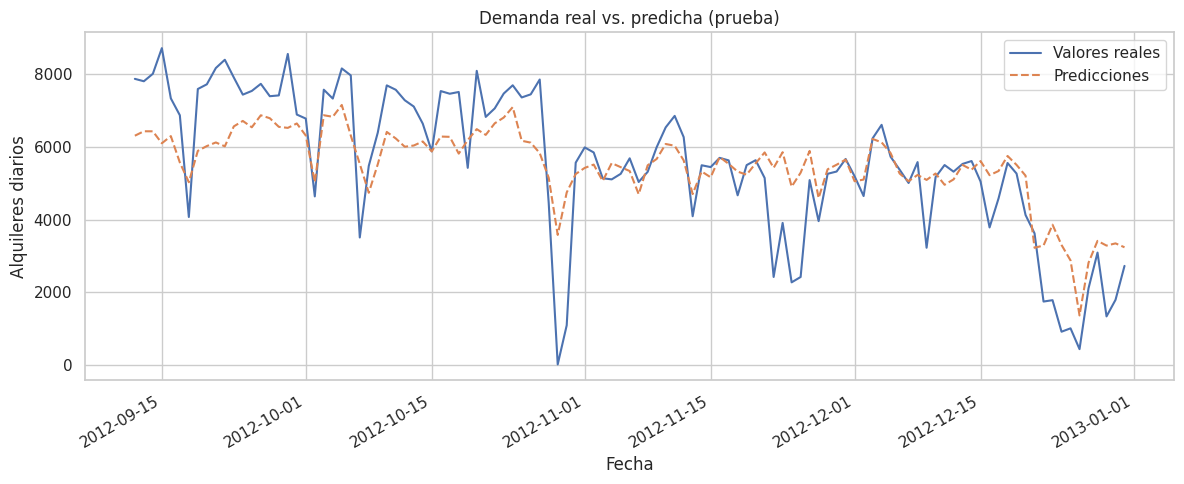

Evaluación final realizada una sola vez.


In [12]:
if modelo_elegido=='multiple':
    pred_test=modelo_multiple.predict(X_test_procesado)
    met_val=met_multiple
else:
    pred_test=modelo_baseline.predict(test_df[['temp']])
    met_val=met_baseline
met_test=metricas(y_test,pred_test)
evaluacion_final=pd.DataFrame([{'Conjunto':'Validación',**met_val},{'Conjunto':'Prueba',**met_test}])
display(evaluacion_final.round(4))
resultados=test_df[['dteday','cnt','temp','hum','windspeed','workingday','weathersit']].copy()
resultados['prediccion']=pred_test
resultados['residuo']=resultados['cnt']-resultados['prediccion']
resultados.to_csv(SALIDA/'predicciones_prueba.csv',index=False)
evaluacion_final.to_csv(SALIDA/'metricas_finales.csv',index=False)
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(resultados.dteday,resultados.cnt,label='Valores reales')
ax.plot(resultados.dteday,resultados.prediccion,label='Predicciones',linestyle='--')
ax.set(title='Demanda real vs. predicha (prueba)',xlabel='Fecha',ylabel='Alquileres diarios')
ax.legend();fig.autofmt_xdate();fig.tight_layout();fig.savefig(SALIDA/'02_real_vs_predicho.png',dpi=150);plt.show()
assert np.isfinite(pred_test).all() and len(pred_test)==len(test_df)
print('Evaluación final realizada una sola vez.')

## 10. Diagnóstico y gráficos complementarios
Los residuos (`real − predicho`) permiten detectar sesgo y valores extremos. Los gráficos de exploración describen el conjunto de datos; no se usan para ajustar transformaciones ni seleccionar modelos a partir de prueba.

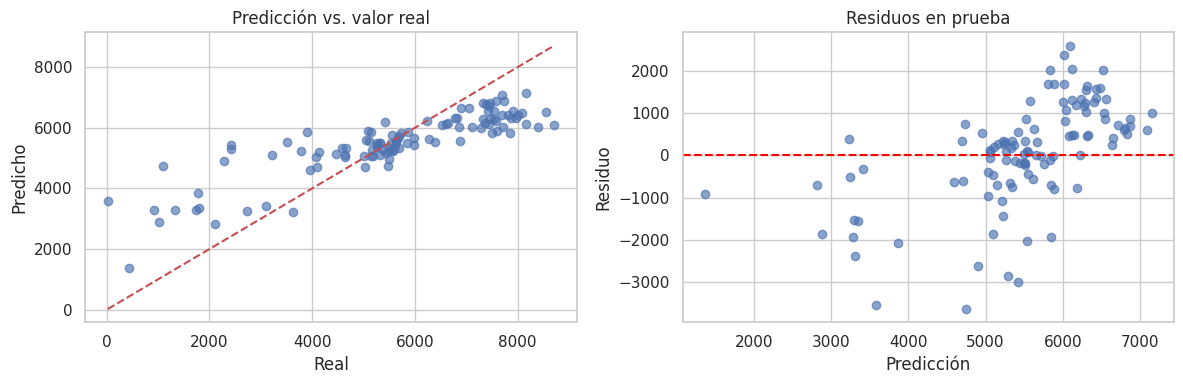

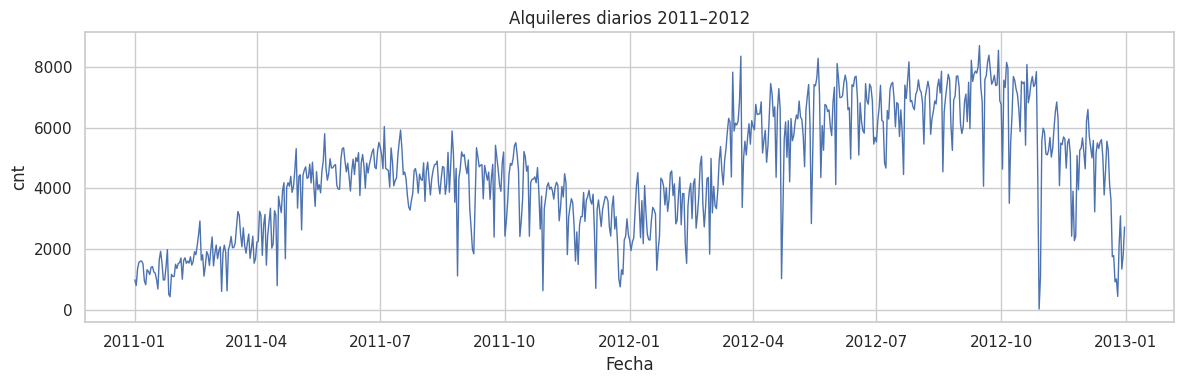

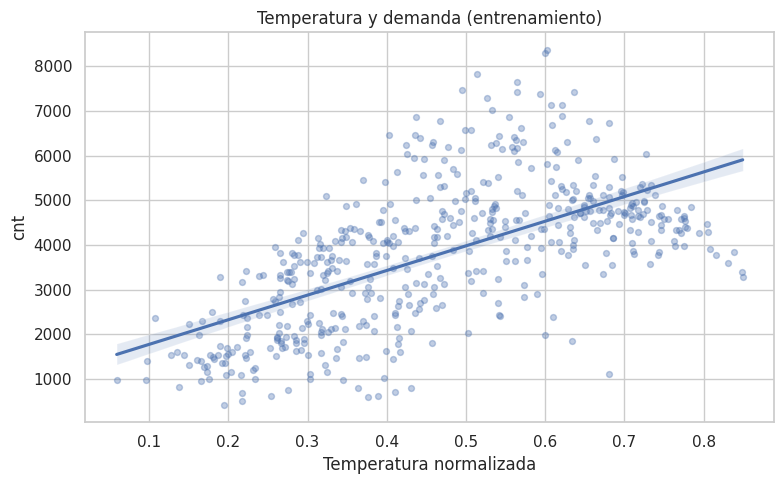

In [13]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(resultados.cnt,resultados.prediccion,alpha=.65)
lo=min(resultados.cnt.min(),resultados.prediccion.min());hi=max(resultados.cnt.max(),resultados.prediccion.max())
axs[0].plot([lo,hi],[lo,hi],'r--');axs[0].set(xlabel='Real',ylabel='Predicho',title='Predicción vs. valor real')
axs[1].scatter(resultados.prediccion,resultados.residuo,alpha=.65)
axs[1].axhline(0,color='red',linestyle='--');axs[1].set(xlabel='Predicción',ylabel='Residuo',title='Residuos en prueba')
fig.tight_layout();fig.savefig(SALIDA/'03_diagnostico_residuos.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(df.dteday,df.cnt,lw=1);ax.set(title='Alquileres diarios 2011–2012',xlabel='Fecha',ylabel='cnt')
fig.tight_layout();fig.savefig(SALIDA/'04_serie_temporal.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(8,5))
sns.regplot(data=train_df,x='temp',y='cnt',scatter_kws={'alpha':.35,'s':18},ax=ax)
ax.set(title='Temperatura y demanda (entrenamiento)',xlabel='Temperatura normalizada',ylabel='cnt')
fig.tight_layout();fig.savefig(SALIDA/'05_dispersion_entrenamiento.png',dpi=150);plt.show()

## 11. Visualización interactiva y dashboard (Plotly)
Se conservan las funcionalidades del notebook original, adaptadas a las predicciones y particiones **70/15/15**.

In [14]:
fig=go.Figure()
fig.add_trace(go.Scatter(x=resultados.dteday,y=resultados.cnt,name='Real',mode='lines+markers'))
fig.add_trace(go.Scatter(x=resultados.dteday,y=resultados.prediccion,name='Predicción final',mode='lines'))
fig.update_layout(title='Predicciones en prueba (70/15/15)',xaxis_title='Fecha',yaxis_title='Alquileres',hovermode='x unified')
fig.write_html(str(SALIDA/'06_comparacion_interactiva.html'),include_plotlyjs=True)
fig.show()

In [15]:
from plotly.subplots import make_subplots
panel=make_subplots(rows=2,cols=2,specs=[[{'colspan':2},None],[{},{}]],subplot_titles=('Demanda diaria','Distribución de alquileres','Temperatura y demanda'),vertical_spacing=.15)
anos=sorted(df['dteday'].dt.year.unique())
for i,ano in enumerate(anos):
    sub=df[df['dteday'].dt.year==ano]
    visible=(i==0)
    panel.add_trace(go.Scatter(x=sub.dteday,y=sub.cnt,mode='lines',name=f'Demanda {ano}',visible=visible),row=1,col=1)
    panel.add_trace(go.Histogram(x=sub.cnt,nbinsx=25,name=f'Distribución {ano}',visible=visible),row=2,col=1)
    panel.add_trace(go.Scatter(x=sub.temp,y=sub.cnt,mode='markers',marker={'opacity':.4,'size':5},name=f'Temperatura {ano}',visible=visible),row=2,col=2)
botones=[]
for i,ano in enumerate(anos):
    vis=[j//3==i for j in range(3*len(anos))]
    botones.append(dict(label=str(ano),method='update',args=[{'visible':vis},{'title':f'Dashboard de alquileres de bicicletas — {ano}'}]))
panel.update_layout(height=800,title=f'Dashboard de alquileres de bicicletas — {anos[0]}',template='plotly_white',updatemenus=[dict(buttons=botones,direction='down',x=1,y=1.14,xanchor='right',yanchor='top')],showlegend=False)
panel.update_xaxes(title_text='Fecha',row=1,col=1);panel.update_yaxes(title_text='Alquileres',row=1,col=1)
panel.update_xaxes(title_text='Alquileres diarios',row=2,col=1);panel.update_yaxes(title_text='Frecuencia',row=2,col=1)
panel.update_xaxes(title_text='Temperatura normalizada',row=2,col=2);panel.update_yaxes(title_text='Alquileres',row=2,col=2)
panel.write_html(str(SALIDA/'07_dashboard_interactivo.html'),include_plotlyjs=True)
panel.show()

## 12. Análisis complementario en R (opcional)
El notebook original incluía `lm()` y `ggplot2`. Para conservarlos **sin crear otra partición**, exportamos las **mismas matrices de entrenamiento y prueba** utilizadas por Python. R ajusta un modelo lineal equivalente, y verificamos las predicciones contra Python. La ejecución requiere `Rscript`; en Colab se puede instalar con `apt-get`. Esta sección es complementaria y **no cambia la selección realizada en validación**.

In [16]:
nombres=preprocesador.get_feature_names_out().tolist()
# Renombramos columnas para que los nombres sean seguros para fórmulas de R.
nombres_r=[f'x{i:02d}' for i in range(len(nombres))]
r_train=pd.DataFrame(X_train_procesado,columns=nombres_r)
r_train.insert(0,'cnt',y_train.to_numpy())
r_test=pd.DataFrame(X_test_procesado,columns=nombres_r)
r_test.insert(0,'cnt',y_test.to_numpy())
r_train.to_csv(SALIDA/'r_entrenamiento.csv',index=False)
r_test.to_csv(SALIDA/'r_prueba.csv',index=False)
print('Matrices equivalentes exportadas:',r_train.shape,r_test.shape)
print('Variables R:',nombres_r)
print('Para ejecutar R, debe estar instalado Rscript.')

Matrices equivalentes exportadas: (511, 18) (111, 18)
Variables R: ['x00', 'x01', 'x02', 'x03', 'x04', 'x05', 'x06', 'x07', 'x08', 'x09', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16']
Para ejecutar R, debe estar instalado Rscript.


In [17]:
if shutil.which('Rscript') is None:
    print('Rscript no está instalado. En Colab puede instalarse con:')
    print('!apt-get update -qq && apt-get install -y -qq r-base-core r-cran-ggplot2')
else:
    print('Rscript disponible:',shutil.which('Rscript'))

Rscript disponible: /usr/bin/Rscript


In [18]:
codigo_r = r'''args <- commandArgs(trailingOnly=TRUE)
ruta <- args[1]
train <- read.csv(file.path(ruta,'r_entrenamiento.csv'),check.names=FALSE)
test <- read.csv(file.path(ruta,'r_prueba.csv'),check.names=FALSE)
modelo_multiple_r <- lm(cnt ~ .,data=train)
cat('Resumen de regresión múltiple en R\n')
print(summary(modelo_multiple_r))
pred <- predict(modelo_multiple_r,newdata=test)
write.csv(data.frame(real=test$cnt,prediccion_R=pred),file.path(ruta,'predicciones_R.csv'),row.names=FALSE)
if (requireNamespace('ggplot2',quietly=TRUE)) {
  library(ggplot2)
  g <- ggplot(data.frame(real=test$cnt,predicho=pred),aes(x=real,y=predicho)) +
       geom_point(alpha=.5) + geom_abline(slope=1,intercept=0,linetype='dashed') +
       labs(title='Predicción múltiple en R (prueba)',x='Real',y='Predicho') + theme_minimal()
  ggsave(file.path(ruta,'07_regresion_R.png'),g,width=8,height=5,dpi=150)
}
'''
(SALIDA/'analisis_R.R').write_text(codigo_r,encoding='utf-8')
if shutil.which('Rscript'):
    proceso=subprocess.run(['Rscript',str(SALIDA/'analisis_R.R'),str(SALIDA.resolve())],capture_output=True,text=True)
    print(proceso.stdout[-3500:])
    if proceso.returncode: raise RuntimeError(proceso.stderr)
    pred_r=pd.read_csv(SALIDA/'predicciones_R.csv')
    # La equivalencia es con el modelo múltiple entrenado en Python, no con un baseline seleccionado.
    pred_python_multiple=modelo_multiple.predict(X_test_procesado)
    diferencia=np.max(np.abs(pred_r.prediccion_R.to_numpy()-pred_python_multiple))
    print('Diferencia máxima R vs Python:',diferencia)
    assert np.allclose(pred_r.prediccion_R,pred_python_multiple,atol=1e-4)
    print('Equivalencia entre lm() y LinearRegression: confirmada.')
else:
    print('Se generó analisis_R.R, pero no se ejecutó: falta Rscript.')

Resumen de regresión múltiple en R

Call:
lm(formula = cnt ~ ., data = train)

Residuals:
    Min      1Q  Median      3Q     Max 
-2833.8  -364.7    51.7   431.0  3213.9 

Coefficients: (5 not defined because of singularities)
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  4960.16     279.93  17.719  < 2e-16 ***
x00           988.91     147.12   6.722 4.93e-11 ***
x01          -138.18      97.57  -1.416  0.15737    
x02          -216.07      33.23  -6.502 1.92e-10 ***
x03          -102.03     178.92  -0.570  0.56877    
x04         -1426.23     107.10 -13.317  < 2e-16 ***
x05          -378.20     103.08  -3.669  0.00027 ***
x06          -762.08     131.26  -5.806 1.14e-08 ***
x07               NA         NA      NA       NA    
x08          1678.52     194.31   8.638  < 2e-16 ***
x09          1301.27     182.39   7.134 3.45e-12 ***
x10               NA         NA      NA       NA    
x11          -532.39     187.74  -2.836  0.00476 ** 
x12               NA         N

## 13. Conclusiones basadas en resultados
Se calculan a partir de las métricas obtenidas, evitando conclusiones predeterminadas. El cambio temporal entre 2011 y 2012 y la dificultad de predecir días extremos deben discutirse como limitaciones potenciales, no como causas demostradas.

In [19]:
print('=== RESUMEN REPRODUCIBLE ===')
print('Datos:',len(df),'registros; nulos:',int(df.isna().sum().sum()))
print('Partición:',len(train_df),'entrenamiento,',len(val_df),'validación,',len(test_df),'prueba')
print('Outliers IQR:');print(tabla_outliers[['Variable','Outliers','Porcentaje']].round(2).to_string(index=False))
print('Modelo seleccionado por MAE de validación:',modelo_elegido)
print(f'Baseline MAE val: {mae_baseline:.2f}; múltiple MAE val: {mae_multiple:.2f}')
print(f'MAE prueba: {met_test["MAE"]:.2f}; RMSE prueba: {met_test["RMSE"]:.2f}; R² prueba: {met_test["R2"]:.4f}')
print('Interpretación: los resultados corresponden a una partición temporal única; el test no se usó para seleccionar modelos.')
assert len(df_modelo)==len(df)==len(train_df)+len(val_df)+len(test_df)
assert len(resultados)==len(test_df)
print('Comprobaciones finales superadas.')

=== RESUMEN REPRODUCIBLE ===
Datos: 731 registros; nulos: 0
Partición: 511 entrenamiento, 109 validación, 111 prueba
Outliers IQR:
 Variable  Outliers  Porcentaje
      cnt         0        0.00
     temp         0        0.00
      hum         2        0.27
windspeed        13        1.78
Modelo seleccionado por MAE de validación: multiple
Baseline MAE val: 1681.24; múltiple MAE val: 730.28
MAE prueba: 937.78; RMSE prueba: 1231.98; R² prueba: 0.6218
Interpretación: los resultados corresponden a una partición temporal única; el test no se usó para seleccionar modelos.
Comprobaciones finales superadas.


## 14. Exportación de evidencias
El ZIP incluye CSV, figuras, HTML interactivo y script R. El `.ipynb` se descarga por separado desde **Archivo → Descargar → Descargar .ipynb** en Google Colab.

In [20]:

# Generar paquete de evidencias local.

archivo_zip = shutil.make_archive(
    str(SALIDA.parent / "evidencias_fase2"),
    "zip",
    root_dir=SALIDA
)

print("Evidencias:", archivo_zip)

for archivo in sorted(SALIDA.iterdir()):
    print(" -", archivo.name)


Evidencias: /content/Bike-Sharing-Analytics/results/reproduccion/evidencias_fase2.zip
 - 01_outliers.png
 - 02_real_vs_predicho.png
 - 03_diagnostico_residuos.png
 - 04_serie_temporal.png
 - 05_dispersion_entrenamiento.png
 - 06_comparacion_interactiva.html
 - 07_dashboard_interactivo.html
 - 07_regresion_R.png
 - analisis_R.R
 - datos_ordenados.csv
 - metricas_finales.csv
 - metricas_validacion.csv
 - predicciones_R.csv
 - predicciones_prueba.csv
 - r_entrenamiento.csv
 - r_prueba.csv


## Referencias
- Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894
- Scikit-learn Developers. *ColumnTransformer, Pipeline, OneHotEncoder, StandardScaler y LinearRegression*. https://scikit-learn.org/stable/
- McKinney, W. *pandas documentation*. https://pandas.pydata.org/
- Matplotlib Development Team. *Matplotlib documentation*. https://matplotlib.org/
- R Core Team. *R: A Language and Environment for Statistical Computing*. https://www.r-project.org/
- Wickham, H. *ggplot2*. https://ggplot2.tidyverse.org/
